<a href="https://colab.research.google.com/github/Amukta2906/beginning-bioinformatics/blob/main/Copy_of_Module10_Classifiers_Responder_vs_Nonresponder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Amukta Chaganty     1002251924

# Module 10 · Classifiers: Predicting Treatment Response from Gene Expression
### Two-class sequence · Lecture 1 (models) → Lecture 2 (evaluation)

**Biological question:** *Can pretreatment gene-expression measurements predict whether a tumor will respond to therapy?*

The data labels are **Responder (0)** and **Nonresponder (1)**.

This notebook builds on our earlier supervised (regression) and unsupervised (PCA/clustering) exercises. We briefly introduce **t-SNE and UMAP** as additional unsupervised visualization methods, then compare **Logistic Regression, Support Vector Machines (SVM), and Random Forests**. Lecture 2 assesses whether those predictions generalize.

**Data:** 600 simulated tumors × 80 simulated normalized expression measurements, with measured binary treatment response and a technical batch effect. The label is a treatment *outcome*, the nonresponder class is simulated to be less common, as is typical at the drug-trial stage.

**Learning Objectives**
1. Contrast PCA, t-SNE, and UMAP; explain why an unsupervised projection does not prove biological subtypes.
2. Explain and visualize Logistic Regression, RBF SVM (`C`, `gamma`), and Random Forest.
3. Perform stratified splitting, leakage-safe Pipelines, StratifiedKFold, and GridSearchCV.
4. Interpret TN / FP / FN / TP, sensitivity (recall), specificity, precision, F1, ROC-AUC, and average precision (PR) for a named positive class.
5. Select models and thresholds without using held-out test labels; separate predictive association from causal inference.

**Assignment:** Answer each **Predict** prompt *before* the next code cell, and **Explain** using its output. Edit the **_Your response here_** text in the existing Markdown cells—**do not add new cells**. Save your executed notebook and submit the GitHub links in Canvas.

**Pacing:** Lecture 1: Sections 0–5, including t-SNE/UMAP context. Lecture 2: Sections 6–10, including validation, threshold selection, ROC and PR curves.


## 0) Setup and reproducibility
This notebook uses NumPy, pandas, matplotlib, scipy, and scikit-learn. **UMAP is optional**, because it uses a separate package. In Colab, the setup cell installs it if necessary; outside Colab, the other exercises still run if UMAP is unavailable.

In [1]:
import sys, importlib.util, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if importlib.util.find_spec('umap') is None and IN_COLAB:
    print('Installing optional UMAP package in Colab (once per runtime)...')
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'umap-learn'])

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import expit
from pathlib import Path
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, classification_report
)

SEED = 42
BLUE, ORANGE, GREEN, PURPLE = '#0072B2', '#D55E00', '#009E73', '#CC79A7'
plt.rcParams.update({'figure.dpi':105,'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False})
OUT = Path('classifier_outputs'); OUT.mkdir(exist_ok=True)

def finish(filename):
    plt.tight_layout()
    plt.savefig(OUT / f'{filename}.png', dpi=150, bbox_inches='tight')
    plt.show()

def metrics(y_true, prediction):
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y_true,prediction),
            'balanced_accuracy':balanced_accuracy_score(y_true,prediction),
            'sensitivity / recall':recall_score(y_true,prediction,zero_division=0),
            'specificity':tn/(tn+fp),
            'precision':precision_score(y_true,prediction,zero_division=0),
            'F1':f1_score(y_true,prediction,zero_division=0),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

def show_cm(ax, truth, predictions, title):
    ConfusionMatrixDisplay.from_predictions(
        truth, predictions, labels=[0,1], display_labels=['Responder','Nonresponder'],
        cmap='Blues', colorbar=False, ax=ax, values_format='d')
    ax.set_title(title)

print('Python:',sys.version.split()[0], '| scikit-learn:',sklearn.__version__)

Python: 3.13.16 | scikit-learn: 1.6.1


## 1) Define the problem: samples, features, and labels **(Slides 1-6)**

In unsupervised learning we explored expression structure *without* known labels. Here the scientific question is supervised: given expression and **observed treatment response** for training tumors, can we predict outcomes for new tumors?

The simulated dataset has **600 tumors × 80 expression features**, with **Responder (0)** more common than **Nonresponder (1)**. A **technical batch effect** changes some expression features but is not programmed to cause the treatment outcome. Batch is not an input to the classifiers.

We split the data into **TRAIN (60%)**, **VALIDATION (20%)**, and untouched **TEST (20%)** before modeling.

* **Stratification** *preserves the response proportions in each partition.*


**Predict (before running):** What label would an always-Responder baseline assign to every tumor? Could it have reasonably high **accuracy** while detecting **zero nonresponders**? What would its statistical **sensitivity** be for the nonresponder class?

**Your response:** It would call every tumor a Responder. Since responders are the majority, accuracy could still look decent (roughly the responder proportion, maybe ~75–80%), but it would find zero nonresponders, so sensitivity for the nonresponder class = 0/(0+FN) = 0. High accuracy here hides a useless classifier.


In [2]:
rng = np.random.default_rng(53)
n, p = 600, 80
program_a = rng.normal(size=n)
program_b = rng.normal(size=n)
batch = rng.integers(0,2,size=n)

# Simulated continuous normalized/log-like expression: NOT read counts.
gene_baselines = rng.normal(6.0,0.45,p)
X_all = gene_baselines + rng.normal(0, 0.95, size=(n,p))
X_all[:, 0:15] += 0.95*program_a[:,None]
X_all[:,15:30] += 0.90*program_b[:,None]
X_all[:,30:40] += 0.36*program_a[:,None] - 0.30*program_b[:,None]
X_all[:,45:70] += 2.00*batch[:,None]  # independent batch-driven expression

# Latent biology changes odds of nonresponse; neither response nor batch is a feature.
nonresponse_prob = expit(-2.25 + 1.60*program_a - 1.45*program_b
                        + 0.35*program_a*program_b)
y_all = rng.binomial(1, nonresponse_prob)
GENES = [f'Gene_{i+1:02d}' for i in range(p)]
ids = np.arange(n)

trainval_idx, test_idx = train_test_split(ids, test_size=0.20,
        stratify=y_all, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.25,
        stratify=y_all[trainval_idx], random_state=SEED)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

assert len(set(train_idx)&set(test_idx)) == 0
assert len(set(train_idx)&set(val_idx)) == 0
print('TRAIN: ',X_train.shape, '  VAL: ',X_val.shape,'  TEST (do not inspect yet): ',X_test.shape)
print('Train class proportions:',pd.Series(y_train).map({0:'Responder',1:'Nonresponder'}).value_counts(normalize=True).round(3).to_dict())
display(pd.DataFrame(X_train[:4,:6], columns=GENES[:6]).round(2))
print('Always-Responder TRAINING accuracy:',round((y_train==0).mean(),3))
print('Always-Responder sensitivity for nonresponders:',0.0)

TRAIN:  (360, 80)   VAL:  (120, 80)   TEST (do not inspect yet):  (120, 80)
Train class proportions: {'Responder': 0.778, 'Nonresponder': 0.222}


,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06
0,7.00,5.92,6.85,5.68,5.36,7.99
1,8.30,5.95,6.42,7.85,7.61,8.18
2,8.54,4.94,6.55,5.89,4.92,5.39
3,8.23,9.01,8.60,7.00,6.23,7.62


Always-Responder TRAINING accuracy: 0.778
Always-Responder sensitivity for nonresponders: 0.0


In [3]:
### Uncomment the line below to visulaize the dataframe with features and label data stitched together. ###
display(pd.DataFrame(X_train, columns=GENES).assign(Response=np.where(y_train == 1, "Nonresponder", "Responder"), Batch=np.asarray(batch)[train_idx]))

,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06,Gene_07,Gene_08,Gene_09,Gene_10,...,Gene_73,Gene_74,Gene_75,Gene_76,Gene_77,Gene_78,Gene_79,Gene_80,Response,Batch
0,7.004987,5.919840,6.848830,5.679245,5.355597,7.994914,6.875984,7.989813,6.655276,5.908140,...,5.760716,5.936805,7.772154,6.869916,7.787910,5.931004,5.944981,4.616152,Responder,0
1,8.300304,5.950817,6.424523,7.849450,7.609624,8.180811,6.742865,7.613485,6.487845,6.571483,...,5.878862,6.388857,7.049336,8.805764,6.634344,5.055151,6.830811,5.436944,Responder,0
2,8.539952,4.941443,6.554839,5.894486,4.916984,5.389568,7.196361,5.061244,5.169256,3.632834,...,6.637483,8.208212,5.187800,5.587994,6.114678,5.206840,8.437442,7.156050,Responder,0
3,8.229490,9.011928,8.601539,7.003099,6.231945,7.617015,6.101111,5.842449,6.601932,6.971283,...,6.747729,5.081223,5.392759,7.018431,6.953676,6.189478,4.955344,4.826979,Responder,0
4,4.259742,5.504551,6.106807,7.017249,8.528607,5.622370,3.873707,6.439153,6.099389,7.394897,...,5.079320,5.757006,4.809115,7.336138,7.279333,7.644594,6.020960,7.170251,Responder,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,5.590103,5.552149,5.550824,6.735005,6.848968,6.797098,8.450509,5.644214,4.753232,6.161704,...,7.252346,8.355641,4.747582,5.772471,6.373836,7.021573,4.779336,5.379120,Responder,1
356,4.968327,5.295636,3.940069,4.763945,5.539707,6.094310,2.806301,4.853025,5.569890,6.223387,...,6.988586,6.920339,6.081640,5.827523,6.294522,8.276822,5.133164,6.613678,Nonresponder,0
357,6.411707,3.903739,3.642530,5.084382,4.897625,6.639723,6.322234,5.757820,6.166264,4.587898,...,4.340008,5.951507,5.537703,6.652434,6.293888,5.848887,4.624818,6.253855,Responder,1
358,6.590923,4.977492,6.030298,7.355501,5.111923,6.169170,5.701814,3.453398,6.281719,6.308020,...,4.794182,6.750777,5.057824,4.789377,7.994035,7.839602,4.878783,6.008822,Responder,1


## 2) Beyond PCA: three ways to visualize high-dimensional samples **(Slides 7-13)**

Last week we used **PCA** to summarize expression variation. This week we add two **nonlinear** approaches, *t-distributed Stochastic Neighbor Embedding (t-SNE)* and *Uniform Manifold Approximation and Projection (UMAP)*. All three compute coordinates using **expression features**, not response labels.

| Method | What it emphasizes | What the axes / distances mean | Important settings |
|---|---|---|---|
| **PCA** | Directions of greatest overall variance; linear combinations of genes | PCs have loadings; explained variance is meaningful. | Centering and scaling; number of PCs |
| **t-SNE** | Preserving similarity among nearby samples in a low-dimensional map | Axes have no gene-specific meaning; between-island distances and island sizes can mislead. | `perplexity` (roughly the size of a typical neighborhood); random seed |
| **UMAP** | Building and laying out a graph of nearby samples, often preserving some broader structure | Axes have no biological units; spacing and apparent gaps depend on settings. | `n_neighbors` (local vs broader structure); `min_dist` (packing density); random seed |

**Important interpretation limits:** These are *visualizations*. t-SNE and UMAP can make visually compelling islands even when there is no discrete biological subtype. Different settings can change the appearance of those islands. Seeing groups is **not** a classification accuracy measurement or evidence of an underlying mechanism. Later, our classifiers fit the original **80 expression features**, **not** the two plotted coordinates.

We will fit all three on the **TRAIN** samples, after training-only scaling, and *hide the response labels initially*. UMAP requires the optional `umap-learn` library; the code will skip it outside Colab if unavailable.

**Predict (before running):** If PCA, t-SNE, or UMAP shows two islands, does that prove they are Responders and Nonresponders? Suggest one *biological* source and one *technical* source of expression structure.

**Your response:** No. The projections never see the labels, so islands only show that some samples have similar expression. A biological source could be a shared expression program (e.g., a proliferation or immune pathway). A technical source could be batch, processing date, or sequencing site.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


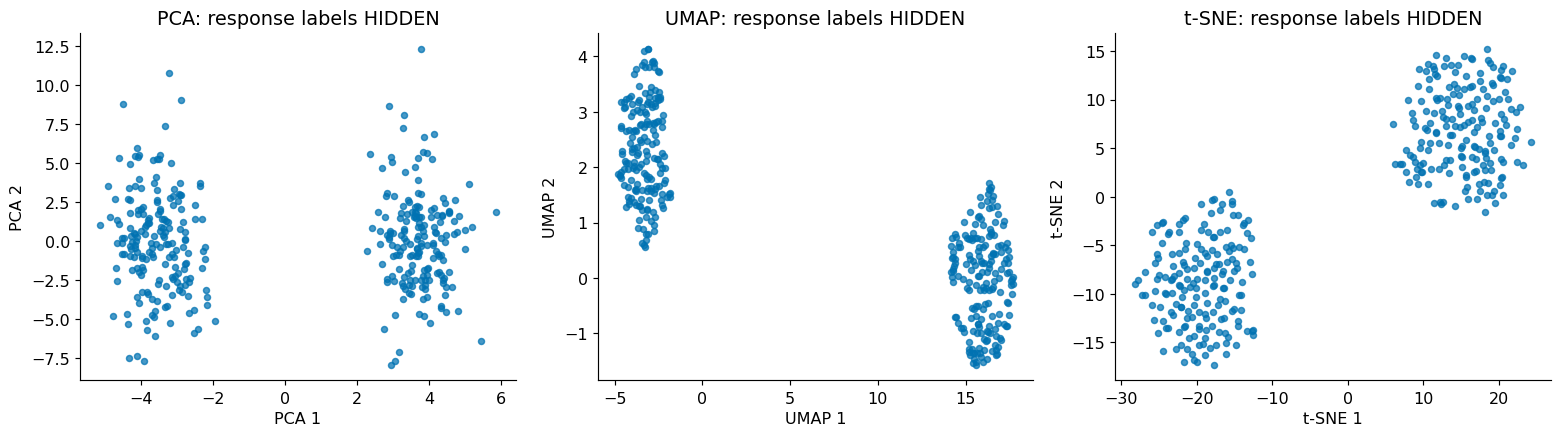

PCA variance explained by first two PCs: [0.171 0.122]


In [4]:
visual_scaler = StandardScaler().fit(X_train)  # TRAIN only
Z_train = visual_scaler.transform(X_train)
pca_vis = PCA(n_components=2, random_state=SEED).fit(Z_train)
pc_train = pca_vis.transform(Z_train)
ts_train = TSNE(n_components=2, init='pca', learning_rate='auto',
                perplexity=30, random_state=SEED).fit_transform(Z_train)
embeddings = [('PCA',pc_train), ('t-SNE',ts_train)]
try:
    import umap
    um_train = umap.UMAP(n_components=2,n_neighbors=20,min_dist=0.12,
                         random_state=SEED).fit_transform(Z_train)
    embeddings.insert(1, ('UMAP',um_train))
except ImportError:
    print('UMAP skipped outside Colab: install umap-learn if desired.')

fig,axs=plt.subplots(1,len(embeddings),figsize=(5*len(embeddings),4.3))
axs=np.atleast_1d(axs)
for ax,(name,xy) in zip(axs,embeddings):
    ax.scatter(xy[:,0],xy[:,1],s=17,color=BLUE,alpha=.72)
    ax.set(xlabel=f'{name} 1',ylabel=f'{name} 2',title=f'{name}: response labels HIDDEN')
finish('02_unlabeled_embeddings')
print('PCA variance explained by first two PCs:',np.round(pca_vis.explained_variance_ratio_,3))

**Explain (after running, still before revealing labels):** Describe one pattern that appears in the plots. Why does it remain scientifically ambiguous until we examine relevant sample metadata?

**Your response:**The PCA plot splits into two clear groups along PC1, and t-SNE shows two separated clouds. (PC1 and PC2 explain 17.1% and 12.2% of variance.) This is ambiguous because nothing in the plot tells us why the groups exist. They could reflect response, batch, or some other factor until we color by metadata.

### 2a) Why projection settings matter: same tumors, different maps

Changing t-SNE `perplexity` changes the effective neighborhood scale; changing UMAP `n_neighbors` changes how much local vs broader structure shapes its layout. These parameters **do not change the underlying gene-expression matrix**. Notice which apparent islands, shapes, and gaps persist across settings. A change in the picture is not evidence that the tumors changed.

**Predict (before running):** When we change a projection's neighborhood setting, will the locations, gaps, and apparent clusters necessarily remain unchanged? Can you use the size of a t-SNE island to estimate the number of tumors it contains?

**Your response:** No. Changing perplexity or n_neighbors changes how neighborhoods are defined, so locations, gaps and apparent clusters can move or merge. Island size in t-SNE doesn't reliably reflect the number of tumors, since t-SNE distorts densities and distances.

In [ ]:
# Illustrate sensitivity to two neighborhood choices; TRAIN samples only.
projections=[]
for perp in (10,60):
    xy=TSNE(n_components=2,init='pca',learning_rate='auto',
            perplexity=perp,random_state=SEED).fit_transform(Z_train)
    projections.append((f't-SNE · perplexity {perp}',xy))
try:
    import umap
    for neighbors in (8,60):
        xy=umap.UMAP(n_components=2,n_neighbors=neighbors,min_dist=.12,
                     random_state=SEED).fit_transform(Z_train)
        projections.append((f'UMAP · neighbors {neighbors}',xy))
except ImportError:
    pass
fig,axs=plt.subplots(1,len(projections),figsize=(4.6*len(projections),4.0))
for ax,(name,xy) in zip(np.atleast_1d(axs),projections):
    ax.scatter(xy[:,0],xy[:,1],s=12,alpha=.64,color=BLUE)
    ax.set(title=name,xlabel='Projection axis 1',ylabel='Projection axis 2')
finish('02_projection_settings')

**Explain (after running):** Describe one change in the *appearance* of the same tumors when a projection setting changes. Why does this make it risky to interpret every plotted island as a distinct tumor subtype? What sort of independent information would help you assess the biology?

**Your response:** At perplexity 10 the t-SNE map looks more fragmented into small clumps; at perplexity 60 the clouds look smoother and the two main groups stand out more.Since the same tumors produce different-looking islands, an island can be an artifact of the setting, not a subtype. Independent information, like batch/processing metadata, clinical outcome, known marker genes or replication in another cohort, would help judge whether a group is biological.

### 2b) Reveal response labels — then ask what actually drives structure **(Slide 14)**

Now color *the same training embeddings* by observed nonresponse status. We can also color PCA by simulated **technical batch**. This batch information is supplied **only for interpretation**; it is never used as a predictor.

**Predict:** Will every visible structure line up with the nonresponse label? If PCA separates batches more clearly than Nonresponders and Responders, is PCA necessarily wrong?

**Your response:** No. Not every structure should line up with response, because batch also changes 25 genes. If PCA separates batches better than response, PCA isn't wrong. It is doing its job: finding the largest variance, which here may be technical.

In [ ]:
plots=[('PCA by response',pc_train,y_train,('Responder','Nonresponder')),
       ('PCA by technical batch',pc_train,batch[train_idx],('Batch 0','Batch 1'))]
plots += [(f'{name} by response',xy,y_train,('Responder','Nonresponder'))
          for name,xy in embeddings if name!='PCA']
fig,axs=plt.subplots(1,len(plots),figsize=(4.7*len(plots),4.2))
axs=np.atleast_1d(axs)
for ax,(title,xy,labels,names) in zip(axs,plots):
    for lab,col in [(0,BLUE),(1,ORANGE)]:
        mask=(labels==lab)
        ax.scatter(xy[mask,0],xy[mask,1],s=19,alpha=.64,color=col,label=f'{names[lab]} (n={mask.sum()})')
    ax.legend(fontsize=8)
    ax.set(xlabel='Component 1',ylabel='Component 2',title=title)
finish('02_metadata_reveal')

**Explain:** Which metadata variable appears more closely related to the main PCA structure: **response class** or **technical batch**? How does this connect to our earlier question about whether unsupervised clusters represent biologically meaningful subtypes? Can a supervised classifier still extract nonresponse-related signal that is *not* the dominant source of variance?

**Your response:** Technical batch drives the main PCA structure. PC1 cleanly separates Batch 0 vs 1 (mean PC1 ≈ −3.6 vs +3.7), but responders and nonresponders overlap almost completely on PC1. Response is related more to PC2 (nonresponders shifted higher). This shows unsupervised clusters aren't automatically meaningful subtypes; the biggest pattern here is a technical artifact. A supervised classifier can still find nonresponse signal, because it uses the labels to weight the genes that predict response, even when those genes aren't the dominant source of variance.

## 3) Classifier family 1: Logistic Regression **(Slides 15-18)**

Despite the name, **logistic regression is a classifier**. For a binary response, it computes a *linear score* from expression features, then converts that score to a predicted probability using the sigmoid:

$$ z = b + \sum_j w_j x_j, \qquad P(\mathrm{Nonresponder}\mid X)=\frac{1}{1+e^{-z}}. $$

A **decision threshold**, often `0.50`, converts that score into a Nonresponder (1) / Responder (0) prediction. The `C` hyperparameter is the **inverse strength of regularization**: smaller `C` means stronger regularization. Here, as in lecture, we can visualize a 2-gene model; the full predictor later uses all 80 genes.

**Predict:** If `P(nonresponse) = 0.41`, which class will be predicted with threshold `0.50`? With threshold `0.25`? If we increase `Gene_01` and its coefficient is positive, which direction does predicted probability of nonresponse move?

**Your response:** At threshold 0.50, P = 0.41 is predicted Responder (0.41 < 0.50). At 0.25, it is predicted Nonresponder (0.41 ≥ 0.25). If Gene_01's coefficient is positive, increasing Gene_01 raises the predicted probability of nonresponse.

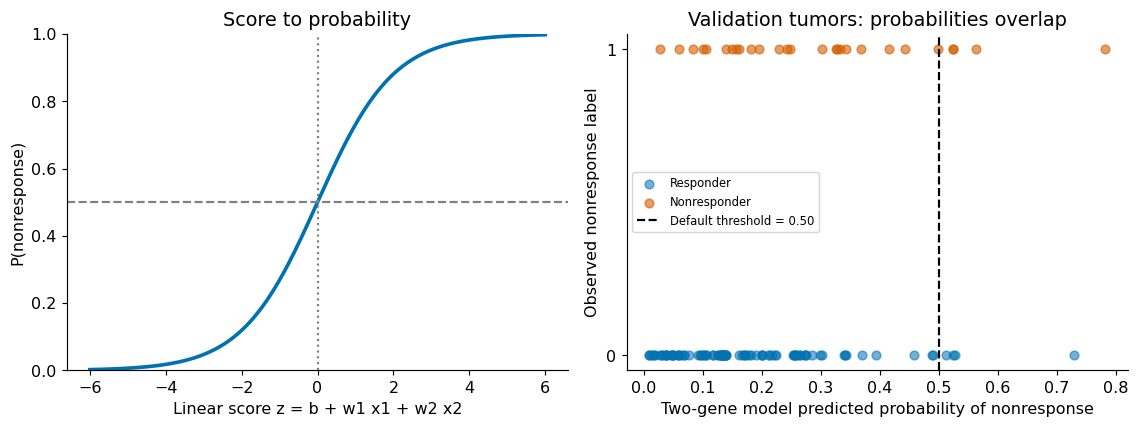

Intercept: -1.621   Standardized gene coefficients: {'Gene_01': np.float64(0.713), 'Gene_16': np.float64(-1.022)}


In [5]:
TWO = [0,15]   # Gene_01 and Gene_16 (one from each latent expression program)
X2_tr, X2_val = X_train[:,TWO], X_val[:,TWO]
logit2 = make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000))
logit2.fit(X2_tr,y_train)
b=float(logit2.named_steps['logisticregression'].intercept_[0])
w=logit2.named_steps['logisticregression'].coef_[0]
z=np.linspace(-6,6,250)
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
axs[0].plot(z,expit(z),color=BLUE,linewidth=2.5)
axs[0].axhline(.5,color='gray',linestyle='--'); axs[0].axvline(0,color='gray',linestyle=':')
axs[0].set(xlabel='Linear score z = b + w1 x1 + w2 x2', ylabel='P(nonresponse)',title='Score to probability',ylim=(0,1))
p2=logit2.predict_proba(X2_val)[:,1]
axs[1].scatter(p2[y_val==0],np.zeros((y_val==0).sum()),color=BLUE,alpha=.55,label='Responder')
axs[1].scatter(p2[y_val==1],np.ones((y_val==1).sum()),color=ORANGE,alpha=.60,label='Nonresponder')
axs[1].axvline(.5,color='black',ls='--',label='Default threshold = 0.50')
axs[1].set(xlabel='Two-gene model predicted probability of nonresponse',ylabel='Observed nonresponse label',yticks=[0,1],title='Validation tumors: probabilities overlap')
axs[1].legend(fontsize=8)
finish('03_logistic_probabilities')
print('Intercept:',round(b,3),'  Standardized gene coefficients:',dict(zip([GENES[j] for j in TWO],np.round(w,3))))

**Explain:** Read the fitted coefficients in the output. Which of these genes increases predicted nonresponse *odds*, holding the other fixed? Are these coefficients causal effects? Why can predicted probabilities overlap even when the classifier has learned a useful signal?

**Your response:** Intercept ≈ −1.62; standardized coefficients Gene_01 ≈ +0.71, Gene_16 ≈ −1.02. Holding the other fixed, higher Gene_01 increases nonresponse odds; higher Gene_16 decreases them. These are not causal effects. They are associations in observational data and could reflect correlated genes or confounders. Probabilities overlap because two genes capture only part of the signal and response is noisy (random), so many responders and nonresponders get similar scores even though the model ranks them better than chance.

# Changing the threshold does not retrain the classifier **(Slide 19)**

**Predict:** Before moving the threshold from 0.50 to 0.20, predict what will happen to sensitivity, specificity, and the number of false positives.

Lowering the threshold from 0.50 to 0.20 should raise sensitivity, lower specificity, and increase false positives.

**Explain:** Move the slider and examine the results. Why do the confusion matrix and performance metrics change even though the logistic regression model has not been retrained? Does lowering the threshold necessarily decrease precision?


The model's probabilities are fixed; only the cutoff that turns probabilities into labels moves, so the counts in the confusion matrix change. For the 2-gene model: at 0.50, TP = 4, FP = 4, FN = 23 (sensitivity 0.15, specificity 0.96); at 0.20, TP = 16, FP = 33, FN = 11 (sensitivity 0.59, specificity 0.65). Precision dropped (0.50 → 0.33) here, but it doesn't have to drop: if the newly flagged tumors are mostly true nonresponders, precision can stay the same or rise.

In [6]:
import ipywidgets as widgets

# Fixed validation probabilities from the trained logistic regression
# p2 was calculated in the preceding cell.
jitter = np.random.default_rng(42).normal(0, 0.04, len(y_val))

@widgets.interact(
    threshold=widgets.FloatSlider(
        value=0.50, min=0.05, max=0.95, step=0.05,
        description="Threshold:",
        continuous_update=False
    )
)
def explore_threshold(threshold):

    # Change classifications WITHOUT retraining the model
    predictions = (p2 >= threshold).astype(int)
    m = metrics(y_val, predictions)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

    # LEFT: Predicted probabilities for each tumor
    for actual, label, color in [
        (0, "Actual Responder", BLUE),
        (1, "Actual Nonresponder", ORANGE)
    ]:
        mask = y_val == actual
        axs[0].scatter(
            p2[mask], y_val[mask] + jitter[mask],
            color=color, alpha=0.65, s=35, label=label
        )

    # Highlight incorrectly classified tumors
    wrong = predictions != y_val
    axs[0].scatter(
        p2[wrong], y_val[wrong] + jitter[wrong],
        marker="x", color="black", s=65,
        label="Incorrect prediction"
    )

    # Decision threshold
    axs[0].axvline(threshold, color="black", linestyle="--",
                   linewidth=2, label=f"Threshold = {threshold:.2f}")

    axs[0].set(
        xlabel="Predicted probability of Nonresponse",
        ylabel="Actual treatment response",
        yticks=[0, 1],
        yticklabels=["Responder", "Nonresponder"],
        xlim=(0, 1),
        ylim=(-0.2, 1.2),
        title="Same probabilities, different classifications"
    )
    axs[0].legend(fontsize=8, loc="upper center")

    # RIGHT: Updated confusion matrix
    show_cm(axs[1], y_val, predictions,
            f"Confusion matrix (threshold = {threshold:.2f})")

    plt.tight_layout()
    plt.show()

    # Updated performance metrics
    display(pd.DataFrame([{
        "Accuracy": m["accuracy"],
        "Sensitivity": m["sensitivity / recall"],
        "Specificity": m["specificity"],
        "Precision": m["precision"],
        "F1": m["F1"]
    }]).round(3))

    print(f"TN={m['TN']}   FP={m['FP']}   FN={m['FN']}   TP={m['TP']}")
    print("Model coefficients and predicted probabilities are unchanged.")

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Threshold:', max=0.95, min=…

## 4) Classifier family 2: Support Vector Machine (SVM) **(Slides 20-22)**

An **SVM** tries to separate labeled classes by a decision boundary with a large margin. A Radial Basis Function (RBF) kernel permits **nonlinear boundaries** without explicitly constructing all transformed coordinates.

The two hyperparameters emphasized in lecture are:

- **`C`**: how strongly to penalize classification errors. Small `C` = more regularization; large `C` = stronger pressure to fit training labels.
- **`gamma`**: how local a training point's influence is in the **RBF kernel**. Small `gamma` = smoother, broad influence; large `gamma` = narrower, more flexible influence.

Below we show Logistic Regression, RBF SVM, and Random Forest **using the same two genes**. These 2D diagrams explain shapes, **not** final 80-gene model selection.

**Predict:** Which family should have a *straight* decision boundary? Which can bend around individual groups? Will increasing `gamma` and `C` always improve predictions on **validation** samples?

**Your response:** Logistic regression has a straight (linear) boundary. RBF SVM and Random Forest can bend around groups (RF makes boxy, axis-aligned regions). Increasing C and gamma won't always help validation; it can overfit training points.

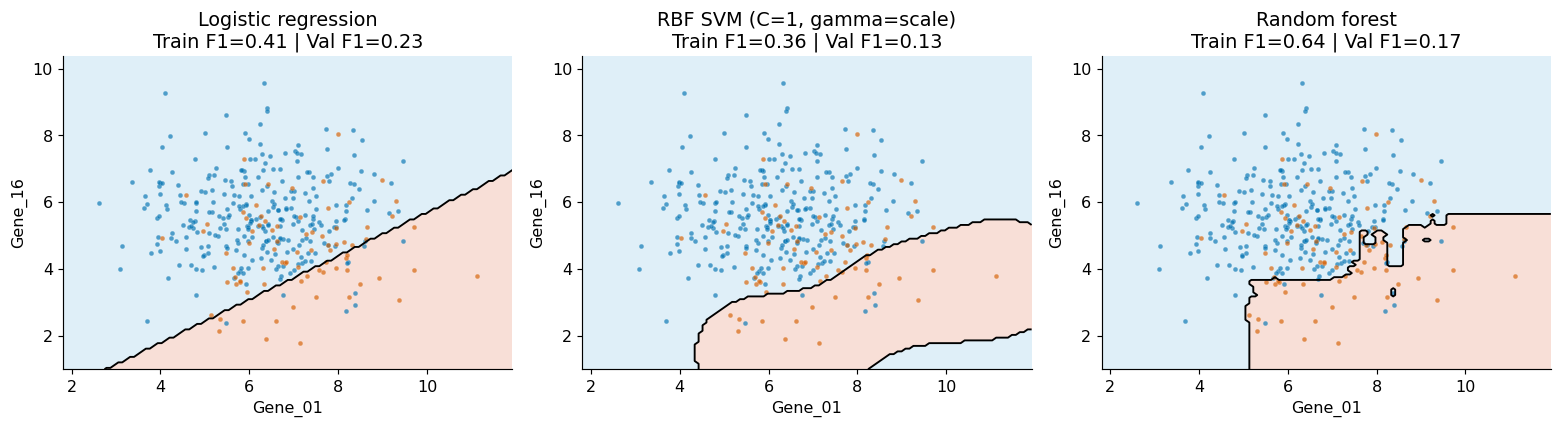

,Classifier,TRAIN F1,VALIDATION F1
0,Logistic regression,0.411,0.229
1,"RBF SVM (C=1, gamma=scale)",0.355,0.129
2,Random forest,0.641,0.167


In [8]:
from matplotlib.colors import ListedColormap

def boundary_panel(ax,model,name):
    model.fit(X2_tr,y_train)
    margin=0.8
    x1=np.linspace(X2_tr[:,0].min()-margin,X2_tr[:,0].max()+margin,115)
    x2=np.linspace(X2_tr[:,1].min()-margin,X2_tr[:,1].max()+margin,115)
    xx,yy=np.meshgrid(x1,x2)
    xy=np.c_[xx.ravel(),yy.ravel()]
    classes=model.predict(xy).reshape(xx.shape)
    ax.contourf(xx,yy,classes,levels=[-.5,.5,1.5],colors=['#D8EBF7','#F7D8CD'],alpha=.8)
    ax.contour(xx,yy,classes,levels=[.5],colors='black',linewidths=1.3)
    for cls,color in [(0,BLUE),(1,ORANGE)]:
        mask=y_train==cls
        ax.scatter(X2_tr[mask,0],X2_tr[mask,1],s=11,alpha=.65,
                   c=color,edgecolors='white',linewidths=.15)
    tr_f1=f1_score(y_train,model.predict(X2_tr),zero_division=0)
    vl_f1=f1_score(y_val,model.predict(X2_val),zero_division=0)
    ax.set(xlabel='Gene_01',ylabel='Gene_16',title=f'{name}\nTrain F1={tr_f1:.2f} | Val F1={vl_f1:.2f}')
    return tr_f1,vl_f1

boundaries={
 'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
 'RBF SVM (C=1, gamma=scale)':make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1,gamma='scale',probability=True,random_state=SEED)),
 'Random forest':RandomForestClassifier(n_estimators=100,max_depth=6,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
}
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
boundary_results=[]
for ax,(name,model) in zip(axs,boundaries.items()):
    train_f1,val_f1=boundary_panel(ax,model,name)
    boundary_results.append((name,train_f1,val_f1))
finish('04_three_classifier_boundaries')
display(pd.DataFrame(boundary_results,columns=['Classifier','TRAIN F1','VALIDATION F1']).round(3))

### 4a) Experiment with `C` and `gamma`
Compare **four RBF SVM settings** with the same training/validation data. The dotted question from lecture is: *when does extra flexibility turn into overfitting?*

**Predict:** Between `C=0.1, gamma=0.03` and `C=50, gamma=5`, which is more likely to fit isolated training observations? Which will necessarily have the better validation F1?

**Your response:**C = 50, gamma = 5 is more likely to fit isolated training points (weak regularization + very local influence). Neither is guaranteed to have better validation F1; it has to be checked.

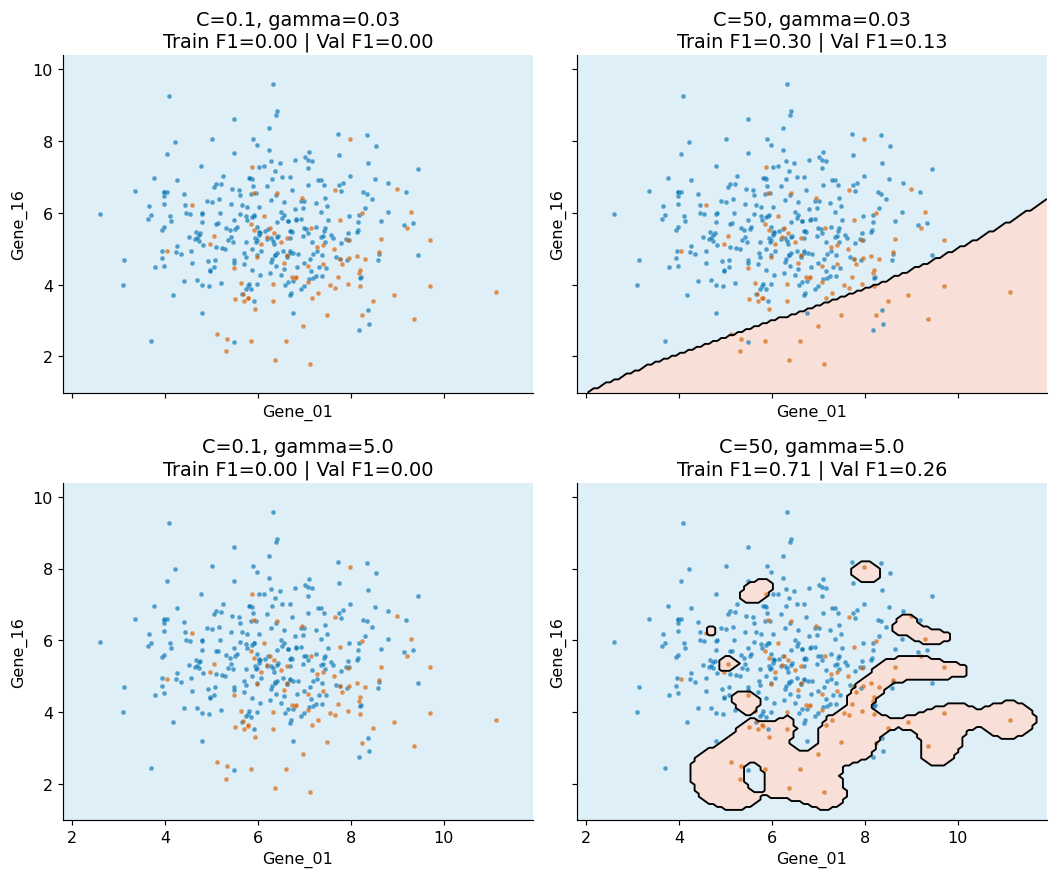

,C,gamma,TRAIN F1,VALIDATION F1
0,0.1,0.03,0.000,0.000
1,50.0,0.03,0.300,0.133
2,0.1,5.00,0.000,0.000
3,50.0,5.00,0.708,0.263


In [9]:
# C and gamma are hyperparameters supplied before training, NOT learned coefficients.
settings=[(.1,.03), (50,.03), (.1,5.0), (50,5.0)]
fig,axs=plt.subplots(2,2,figsize=(10.2,8.5),sharex=True,sharey=True)
rows=[]
for ax,(C,gamma) in zip(axs.flat,settings):
    model=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=C,gamma=gamma,
                       probability=True,random_state=SEED))
    tr,vl=boundary_panel(ax,model,f'C={C}, gamma={gamma}')
    rows.append({'C':C,'gamma':gamma,'TRAIN F1':tr,'VALIDATION F1':vl})
finish('04_svm_c_gamma')
display(pd.DataFrame(rows).round(3))

**Explain:** Point to the panel with the most flexible/complex boundary. Does its training F1 look like a reliable estimate of generalization? Explain one visible instance in which allowing more complex decision boundaries helps or hurts validation performance.

**Your response:** The most complex boundary is C = 50, gamma = 5: training F1 = 0.71 but validation F1 = 0.26. That training F1 badly overestimates generalization — the boundary wraps around individual training points. Low-flexibility settings (C = 0.1) predicted almost no nonresponders (F1 = 0 for both gammas), so too little flexibility hurts too. Moving from C = 0.1 to C = 50 at gamma = 0.03 improved validation F1 from 0 to 0.13, which shows some extra flexibility helps, while the huge gap at gamma = 5 shows overfitting.

## 5) Classifier family 3: Random Forest **(Slides 23-25)**

A **Random Forest** aggregates many decision trees. Each tree uses a **bootstrap sample** of the training observations and considers a random subset of features at a split. Its class probability is typically the **average class probability from the trees**, so it can also be thresholded.

The *impurity-based feature importance* scores (Gini index) indicate which features the trees used to reduce impurity, **not** proof of biological causation. Correlated expression measurements may split importance among themselves.

#### Visualize the first few layers of the first tree in the Random Forest

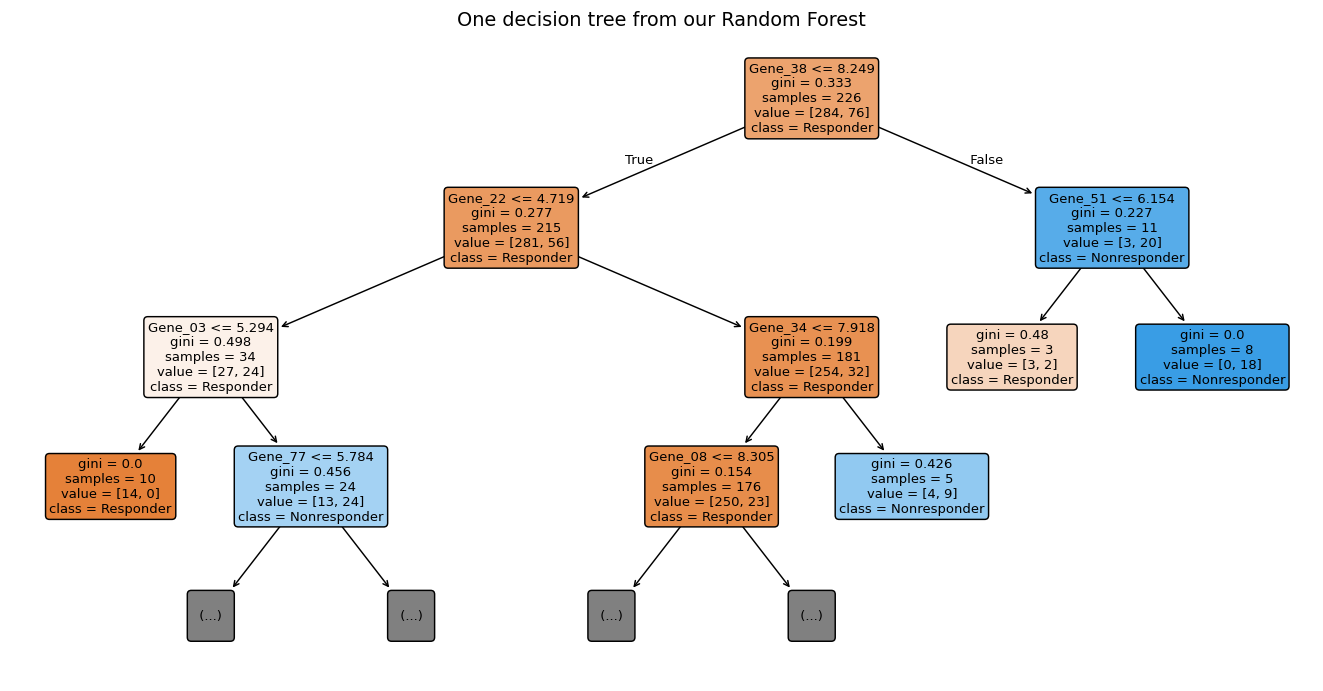

In [10]:
from sklearn.tree import plot_tree

rf_demo=RandomForestClassifier(n_estimators=150,max_depth=7,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
rf_demo.fit(X_train,y_train)

plt.figure(figsize=(16, 8))

plot_tree(
    rf_demo.estimators_[0],
    feature_names=GENES,
    class_names=["Responder", "Nonresponder"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("One decision tree from our Random Forest")
plt.show()

**Predict:** Why might a Random Forest perform better on new samples than a single unpruned decision tree?


A single unpruned tree memorizes noise in its training data (high variance). A forest averages many trees trained on bootstrap samples and random feature subsets, so their errors partly cancel, giving more stable predictions on new samples.

**Explain:** Run the cell below and examine the Random Forest feature-importance plot. Which genes contribute most to classification? Does high feature importance demonstrate that these genes cause treatment nonresponse? Why or why not?

**Your response:** Top genes: Gene_12 (0.056), Gene_06 (0.047), Gene_27, Gene_13, Gene_16, Gene_25 — all from Genes 1–30, the two biological programs. None are batch genes (46–70), which makes sense because batch doesn't affect response. High importance doesn't show causation: it only means the trees used that gene to split, and correlated genes in the same program share importance somewhat arbitrarily. (RF training F1 = 0.90 vs validation F1 = 0.43, which also shows overfitting.)

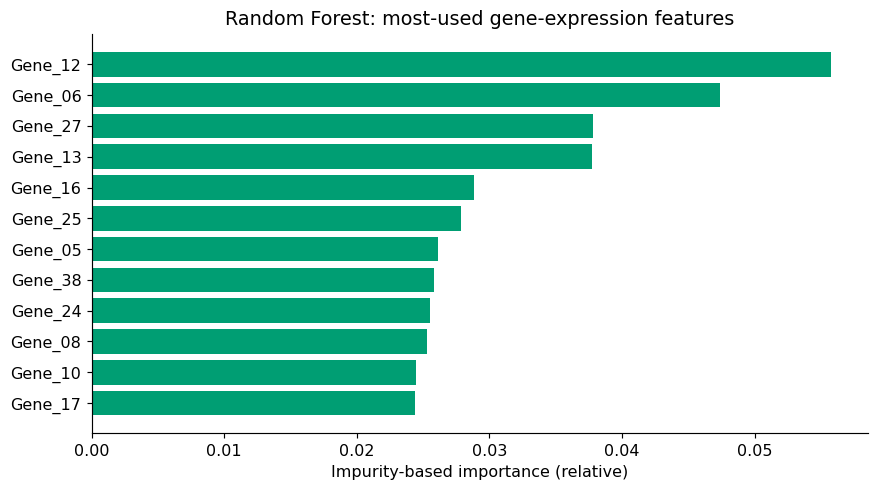

Random Forest training F1: 0.904
Random Forest validation F1: 0.432


In [11]:
important=np.argsort(rf_demo.feature_importances_)[-12:][::-1]
fig,ax=plt.subplots(figsize=(8.5,4.8))
ax.barh([GENES[i] for i in important[::-1]],rf_demo.feature_importances_[important[::-1]],color=GREEN)
ax.set(xlabel='Impurity-based importance (relative)',title='Random Forest: most-used gene-expression features')
finish('05_random_forest_features')
print('Random Forest training F1:',round(f1_score(y_train,rf_demo.predict(X_train)),3))
print('Random Forest validation F1:',round(f1_score(y_val,rf_demo.predict(X_val)),3))

---
# **Lecture 2 · Training, Tuning, and Evaluating Classifiers**

**Checkpoint:** You have seen how three classifier families produce predictions. Now ask whether those predictions are reliable on *new tumors*. In Lecture 2 we choose hyperparameters with training-only cross-validation, choose a decision threshold with validation data, and assess the frozen model once on the test set.

**Recall:** Positive class = **Nonresponder (1)**; **sensitivity** = TP / (TP + FN) for nonresponders.

## 6) Leakage-safe Pipelines, cross-validation and grid search

This section follows the workflow from lecture:

1. Keep the **held-out TEST** samples completely untouched.
2. On the **TRAIN** samples, a scikit-learn **Pipeline** fits preprocessing inside each cross-validation training fold, then learns a classifier.
3. **StratifiedKFold** keeps the positive/negative proportions approximately balanced across folds.
4. **GridSearchCV** evaluates predefined hyperparameter combinations and selects the best **cross-validation** score; we compare the three families.
5. The chosen model is evaluated on **VALIDATION** data to choose an operating threshold; only then do we use the TEST samples **once**.

Why `scoring='average_precision'` instead of just accuracy? In this example, the nonresponse class is less common and **ranking true nonresponders above responder tumors** matters. Average precision summarizes the precision–recall curve, **without fixing a 0.50 threshold**. We will also report ROC-AUC and classification counts.

**Predict:** What leakage occurs if you standardize **all** samples *before splitting*, or use test-set F1 to decide which `C` and `gamma` to use? Is `C` a model parameter or hyperparameter?

**Your response:** Standardizing all samples before splitting lets test/validation means and variances leak into training. Using test-set F1 to pick C and gamma turns the test set into part of tuning, so its score is no longer an honest estimate. C is a hyperparameter (set before training), not a learned parameter.

In [12]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
models={
 'Logistic regression':Pipeline([('scale',StandardScaler()),
                                  ('clf',LogisticRegression(max_iter=2500,random_state=SEED))]),
 'RBF SVM':Pipeline([('scale',StandardScaler()),
                      ('clf',SVC(kernel='rbf',probability=True,random_state=SEED))]),
 'Random Forest':Pipeline([('clf',RandomForestClassifier(random_state=SEED,n_jobs=1))])
}
parameter_grids={
 'Logistic regression':{'clf__C':[.1,1,10]},
 'RBF SVM':{'clf__C':[.1,1,10],'clf__gamma':[.001,'scale',.1]},
 'Random Forest':{'clf__n_estimators':[100,200],'clf__min_samples_leaf':[2,6]}
}

searches={}; cv_rows=[]
for name,pipe in models.items():
    grid=GridSearchCV(pipe,parameter_grids[name],scoring='average_precision',
                      cv=cv,n_jobs=1,refit=True)
    grid.fit(X_train,y_train) # scaler is fitted anew *inside each fold*.
    searches[name]=grid
    cv_rows.append({'Classifier':name,'Mean CV AP':grid.best_score_,
                    'Best hyperparameters':str(grid.best_params_)})
cv_table=pd.DataFrame(cv_rows).sort_values('Mean CV AP',ascending=False).reset_index(drop=True)
display(cv_table.round(3))
chosen_name=cv_table.iloc[0]['Classifier']
chosen_model=searches[chosen_name].best_estimator_
print('Selected by TRAIN-only cross-validated average precision:',chosen_name)
print('Training-only fitted model:',chosen_model)
cv_table.to_csv(OUT/'cv_model_selection.csv',index=False)

,Classifier,Mean CV AP,Best hyperparameters
0,RBF SVM,0.792,"{'clf__C': 0.1, 'clf__gamma': 0.001}"
1,Random Forest,0.742,"{'clf__min_samples_leaf': 6, 'clf__n_estimator..."
2,Logistic regression,0.704,{'clf__C': 0.1}


Selected by TRAIN-only cross-validated average precision: RBF SVM
Training-only fitted model: Pipeline(steps=[('scale', StandardScaler()),
                ('clf',
                 SVC(C=0.1, gamma=0.001, probability=True, random_state=42))])


### 6a) Visualize the SVM grid search

A grid is an explicit, finite search over `C × gamma`. The grid uses gamma = 0.001, `scale`, and 0.1. The `scale` setting automatically computes gamma = 1 / (number of features × variance); with 80 standardized expression features, it is approximately **0.0125**.

Colors below show **mean cross-validated average precision on training folds**; these scores are *not* test performance. A setting is not guaranteed to be optimal just because it wins a small grid.

**Predict:** If the same data are reused to test hundreds of hyperparameter combinations, why might even the best cross-validation score be optimistic? What should remain untouched?

**Your response:** When many combinations are tried, some win partly by luck on those particular folds, so the best CV score is optimistically biased (a winner's-curse effect). The held-out test set must stay untouched.

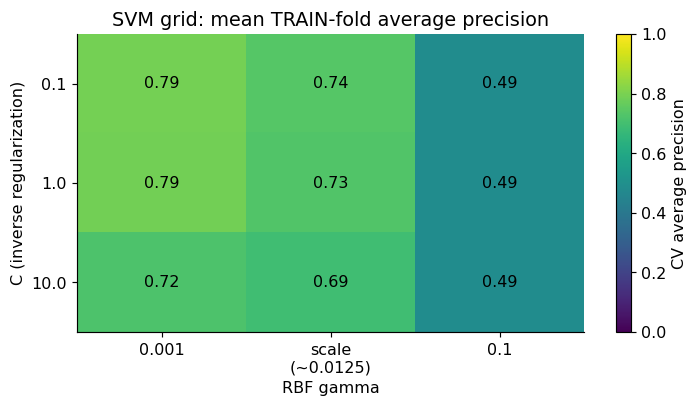

In [13]:
svm_cv=pd.DataFrame(searches['RBF SVM'].cv_results_)
svm_cv['C']=svm_cv['param_clf__C'].astype(float)
svm_cv['gamma']=svm_cv['param_clf__gamma'].astype(str)
pivot=(svm_cv.pivot(index='C',columns='gamma',values='mean_test_score')
       .reindex(columns=['0.001','scale','0.1']))
fig,ax=plt.subplots(figsize=(7.0,4.0))
im=ax.imshow(pivot.to_numpy(),cmap='viridis',aspect='auto',vmin=0,vmax=1)
# 'scale' is approximately 1 / 80 = 0.0125 after StandardScaler.
ax.set_xticks(range(len(pivot.columns)),['0.001','scale\n(~0.0125)','0.1'])
ax.set_yticks(range(len(pivot.index)),pivot.index)
ax.set(xlabel='RBF gamma',ylabel='C (inverse regularization)',
       title='SVM grid: mean TRAIN-fold average precision')
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val=pivot.iloc[i,j]
        ax.text(j,i,f'{val:.2f}',ha='center',va='center',
                color='white' if val<.48 else 'black',fontsize=11)
fig.colorbar(im,ax=ax,label='CV average precision')
finish('06_svm_grid_search')

**Explain:** Which SVM `C`/`gamma` setting achieved the highest mean CV average precision? Which model family won overall? Does that prove the same ranking must hold for a new population or a future laboratory?

**Your response:** Best SVM: C = 0.1, gamma = 0.001, mean CV AP = 0.792 (C = 1, gamma = 0.001 was nearly tied at 0.789). gamma = 0.1 was worst (~0.49 for every C). Overall ranking: RBF SVM 0.792 > Random Forest 0.742 (min_samples_leaf = 6, 200 trees) > Logistic regression 0.704 (C = 0.1). This doesn't prove the ranking holds for a new population or lab; differences are small, the grid is small, and a different cohort, batch or prevalence could change it.

## 7) Classification errors: sensitivity, specificity, precision and F1

From this point forward, evaluate the cross-validation-selected classifier on the **VALIDATION** samples only. **Nonresponder = positive** (`1`).

| | Predicted Responder (`0`) | Predicted Nonresponder (`1`) |
|---|---:|---:|
| **Actually Responder (`0`)** | **TN** = true negative | **FP** = false positive (false alarm) |
| **Actually Nonresponder (`1`)** | **FN** = false negative (missed nonresponse) | **TP** = true positive |

\[ \mathrm{Sensitivity/Recall}=\frac{TP}{TP+FN},\qquad \mathrm{Specificity}=\frac{TN}{TN+FP} \]
\[ \mathrm{Precision}=\frac{TP}{TP+FP},\qquad F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}. \]

A nonresponder incorrectly predicted responder (**FN**) could receive ineffective treatment if this were a legitimate clinical tool. A responder tumor incorrectly predicted nonresponse (**FP**) could be denied an effective treatment. **Neither error has a universal cost**. F1 is a teaching objective here, not a clinical recommendation.

**Predict:** If we **lower** the threshold from `0.50` to `0.20`, will sensitivity tend to rise or fall? What happens to the number of false positives? Must *precision* decrease in every possible dataset?

**Your response:** Sensitivity tends to rise and false positives increase. Precision usually falls but doesn't have to in every dataset; it depends on whether the extra flagged tumors are mostly true nonresponders.

,threshold,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,0.20,0.767,0.771,0.778,0.763,0.488,0.600,71,22,6,21
1,0.35,0.783,0.742,0.667,0.817,0.514,0.581,76,17,9,18
2,0.50,0.800,0.726,0.593,0.860,0.552,0.571,80,13,11,16
3,0.65,0.783,0.650,0.407,0.892,0.524,0.458,83,10,16,11
4,0.80,0.817,0.632,0.296,0.968,0.727,0.421,90,3,19,8


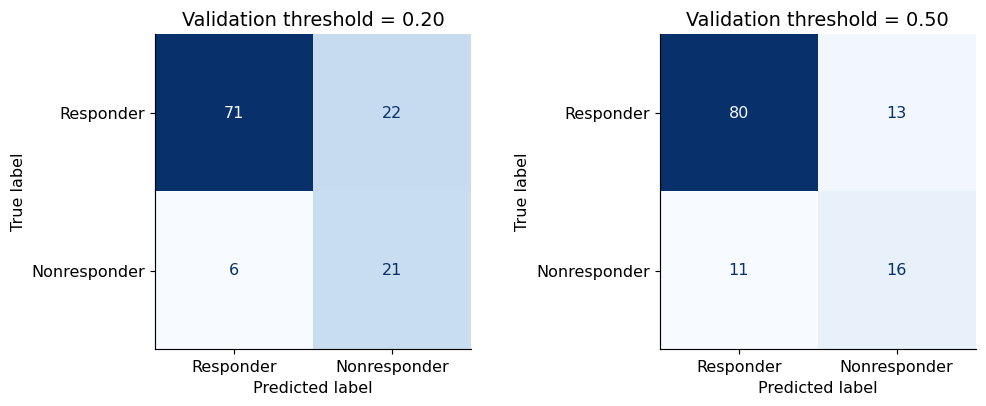

Always-Responder validation baseline: {'accuracy': 0.775, 'balanced_accuracy': np.float64(0.5), 'sensitivity / recall': 0.0, 'specificity': np.float64(1.0), 'precision': 0.0, 'F1': 0.0, 'TN': 93, 'FP': 0, 'FN': 27, 'TP': 0}


In [14]:
val_prob=chosen_model.predict_proba(X_val)[:,1]
THRESHOLDS=[.20,.35,.50,.65,.80]
metrics_by_threshold=pd.DataFrame([
    {'threshold':t,**metrics(y_val,(val_prob>=t).astype(int))}
    for t in THRESHOLDS])
display(metrics_by_threshold.round(3))

fig,axs=plt.subplots(1,2,figsize=(10,4))
show_cm(axs[0],y_val,(val_prob>=.20).astype(int),'Validation threshold = 0.20')
show_cm(axs[1],y_val,(val_prob>=.50).astype(int),'Validation threshold = 0.50')
finish('07_confusion_matrices')

print('Always-Responder validation baseline:',metrics(y_val,np.zeros_like(y_val)))

### 7a) Inspect the threshold tradeoff visually

Each point on this graph is calculated from the **same validation probabilities**; changing the threshold does not retrain the classifier. The 0.50 threshold is not magical, and the tradeoff depends on your scientific objective.

**Predict:** Why might `accuracy` stay respectable even when the classifier misses most nonresponders? What is the key distinction between **sensitivity** and **precision**?

**Your response:** Accuracy is dominated by the large responder class, so a model can miss most nonresponders and still get ~78% right. Sensitivity = the fraction of true nonresponders we catch; precision = the fraction of tumors we flag as nonresponders that really are.

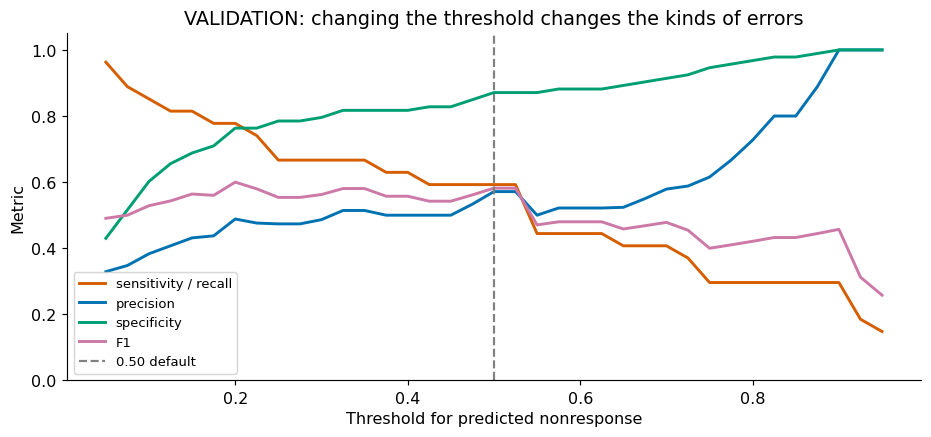

In [15]:
ths=np.arange(.05,.951,.025)
sweep=pd.DataFrame([{'threshold':t,**metrics(y_val,(val_prob>=t).astype(int))}
                   for t in ths])
fig,ax=plt.subplots(figsize=(9,4.3))
for key,color in [('sensitivity / recall',ORANGE),('precision',BLUE),('specificity',GREEN),('F1',PURPLE)]:
    ax.plot(sweep.threshold,sweep[key],label=key,color=color,linewidth=2)
ax.axvline(.5,color='gray',ls='--',label='0.50 default')
ax.set(xlabel='Threshold for predicted nonresponse',ylabel='Metric',ylim=(0,1.05),
       title='VALIDATION: changing the threshold changes the kinds of errors')
ax.legend(loc='best',fontsize=9)
finish('07_threshold_tradeoff')

**Explain:** Copy TP, FP, FN, precision and sensitivity at thresholds **0.20** and **0.50** from the previous table. If the purpose were to **screen for likely nonresponse**, which might you prefer? If the purpose were to limit unnecessary treatment changes, which might you prefer? Explain in terms of errors, not just F1.

**Your response:**
Threshold	TP	FP	FN	Precision	Sensitivity

0.20	21	22	6	0.488	0.778

0.50	16	13	11	0.552	0.593

For screening likely nonresponse, I'd pick 0.20: it misses only 6 nonresponders instead of 11, at the cost of 9 more false alarms. To limit unnecessary treatment changes, I'd pick 0.50 (or higher): fewer responders wrongly flagged (13 vs 22), but more nonresponders missed.

## 8) ROC vs precision–recall: evaluating ranking across thresholds

The **ROC curve** plots **true positive rate (sensitivity)** against **false positive rate = 1 − specificity** at many thresholds. **ROC-AUC** measures the ability to rank nonresponders above responder ones (0.5 is chance-level ranking for a random score).

The **precision–recall (PR) curve** plots precision versus sensitivity. Its approximate no-skill **horizontal baseline equals the proportion of nonresponders**. **Average precision (AP)** is the stepwise-weighted summary of the PR curve; it is *not exactly* trapezoidal area under that curve. In an imbalanced dataset, PR often makes the burden of false-positive predictions more visible than ROC.

**Predict:** Suppose only ~20% of tumors are Nonresponders. If your classifier identifies most nonresponders but also flags many responder tumors, can its ROC curve still look fairly good while precision is mediocre? What baseline values would you expect for ROC-AUC and AP under random ranking?

**Your response:**Yes. ROC uses the false positive rate, which stays small when there are many responders, so the ROC curve can look good while precision is mediocre. Under random ranking, ROC-AUC ≈ 0.5 and AP ≈ the nonresponder proportion (~0.22).

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11.5,4.6))
pr_rows=[]
for name,grid in searches.items():
    proba=grid.best_estimator_.predict_proba(X_val)[:,1]
    fpr,tpr,_=roc_curve(y_val,proba)
    prec,rec,_=precision_recall_curve(y_val,proba)
    auc=roc_auc_score(y_val,proba)
    ap=average_precision_score(y_val,proba)
    axs[0].plot(fpr,tpr,linewidth=2,label=f'{name} · AUC={auc:.2f}')
    axs[1].step(rec,prec,where='post',linewidth=1.7,label=f'{name} · AP={ap:.2f}')
    pr_rows.append({'Classifier':name,'VALIDATION ROC-AUC':auc,'VALIDATION average precision':ap})
axs[0].plot([0,1],[0,1],ls='--',color='gray',label='Random-ranking diagonal')
axs[0].set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
           title='ROC curves · VALIDATION',xlim=(0,1),ylim=(0,1.02))
axs[1].axhline(y_val.mean(),ls='--',color='gray',label=f'No-skill PR baseline = {y_val.mean():.2f}')
axs[1].set(xlabel='Recall / sensitivity',ylabel='Precision',title='Precision–recall curves · VALIDATION',
           xlim=(0,1),ylim=(0,1.02))
for ax in axs: ax.legend(fontsize=8,loc='best')
finish('08_roc_vs_precision_recall')
display(pd.DataFrame(pr_rows).round(3))

**Explain:** Identify the highest validation **ROC-AUC** and **average precision**. Does the best model by ROC-AUC necessarily have the best AP or highest F1 at 0.50? Report the **PR baseline** and explain why class prevalence matters for precision. Does either curve establish **calibration** of predicted probabilities?

**Your response:** Highest validation ROC-AUC and AP were both the RBF SVM (AUC = 0.825, AP = 0.638); logistic 0.816 / 0.606, RF 0.808 / 0.607. The best AUC model doesn't have to have the best AP or F1. Here, logistic and RF have nearly identical AP but RF's F1 at 0.50 is much lower (0.43 vs 0.53). The PR no-skill baseline is 0.225 (27/120 nonresponders). Prevalence matters because precision = TP/(TP+FP): with few positives, even a small false-positive rate creates many false positives relative to true ones. Neither curve shows calibration; they only measure ranking, not whether a predicted 0.30 really means a 30% chance.

## 9) Lock the decision threshold; then open the TEST set **once**

The model family and hyperparameters were chosen by TRAIN-only cross-validation (Section 6). Now choose a threshold on VALIDATION using a fixed candidate list and **validation F1** as a *teaching* objective. In a real study, the threshold must reflect clinical/biological costs and ideally be specified in advance or tuned in an independent validation cohort.

**Do not change your model or threshold after you see the TEST result.** Trying many candidate thresholds can itself overfit the validation set, so the TEST set protects against optimistic selection.

**Predict:** If the held-out test F1 is lower than the validation F1, does that mean the code is wrong? Should you try 10 more thresholds **on the test data** to improve it?

**Your response:** No. A lower test F1 is expected, because the threshold was chosen to maximize validation F1 (optimistic) and the test set is a new random sample. Trying more thresholds on test data would be leakage and would invalidate the test estimate.

In [16]:
# Threshold is selected ONLY with validation samples, while the classifier was selected by TRAIN CV.
threshold_grid=np.round(np.arange(.10,.91,.05),2)
threshold_scores=pd.DataFrame([{
    'threshold':float(t),
    'validation_F1':f1_score(y_val,(val_prob>=t).astype(int),zero_division=0)}
    for t in threshold_grid])
chosen_threshold=float(threshold_scores.sort_values(
    ['validation_F1','threshold'],ascending=[False,True]).iloc[0]['threshold'])
chosen_validation_f1=float(threshold_scores['validation_F1'].max())
print('LOCKED MODEL:',chosen_name)
print('LOCKED THRESHOLD:',chosen_threshold)
print('VALIDATION F1:',round(chosen_validation_f1,3))
print('From this point forward, no further model or threshold tuning is permitted.')

LOCKED MODEL: RBF SVM
LOCKED THRESHOLD: 0.2
VALIDATION F1: 0.6
From this point forward, no further model or threshold tuning is permitted.


### Final held-out evaluation

This is the **first** point in the notebook at which we use the TEST labels. A discrepancy between validation and test performance is expected because of sampling variation and imperfect model selection.

HELD-OUT TEST · RBF SVM · threshold 0.2


,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,0.667,0.68,0.704,0.656,0.373,0.487,61,32,8,19


TEST ROC-AUC: 0.802
TEST average precision: 0.702


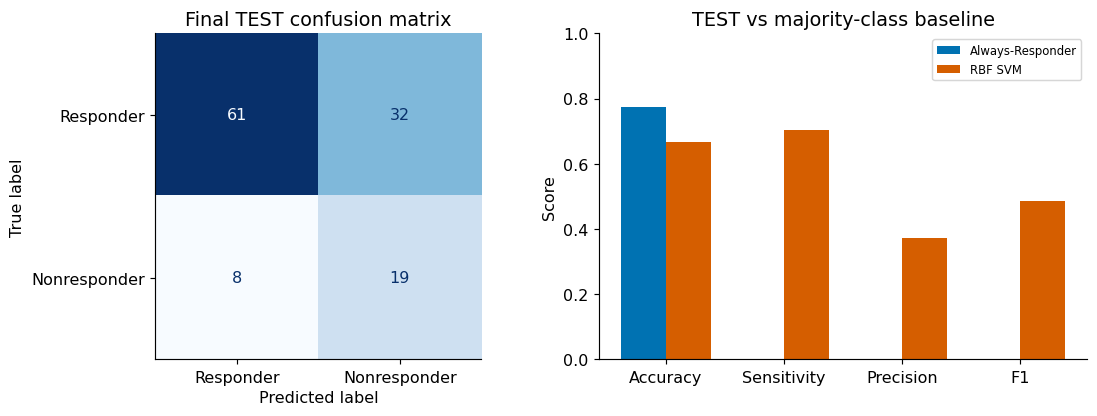

In [17]:
# One evaluation ONLY: do not use these results to retune.
test_probability=chosen_model.predict_proba(X_test)[:,1]
test_prediction=(test_probability>=chosen_threshold).astype(int)
test_metrics=metrics(y_test,test_prediction)
print('HELD-OUT TEST ·',chosen_name,'· threshold',chosen_threshold)
display(pd.DataFrame([test_metrics]).round(3))
print('TEST ROC-AUC:',round(roc_auc_score(y_test,test_probability),3))
print('TEST average precision:',round(average_precision_score(y_test,test_probability),3))

fig,axs=plt.subplots(1,2,figsize=(11,4.1))
show_cm(axs[0],y_test,test_prediction,'Final TEST confusion matrix')
baseline=metrics(y_test,np.zeros_like(y_test))
keys=['accuracy','sensitivity / recall','precision','F1']
xx=np.arange(len(keys))
axs[1].bar(xx-.19,[baseline[k] for k in keys],width=.38,color=BLUE,label='Always-Responder')
axs[1].bar(xx+.19,[test_metrics[k] for k in keys],width=.38,color=ORANGE,label=chosen_name)
axs[1].set_xticks(xx,['Accuracy','Sensitivity','Precision','F1'])
axs[1].set(ylabel='Score',ylim=(0,1),title='TEST vs majority-class baseline')
axs[1].legend(fontsize=8)
finish('09_final_test')

pd.DataFrame({'sample_id':[f'Tumor_{i+1:03d}' for i in test_idx],
              'actual_nonresponder':y_test,'predicted_probability':test_probability,
              'predicted_nonresponder':test_prediction}).to_csv(
                  OUT/'held_out_test_predictions.csv',index=False)

**Explain:** Record the chosen classifier, hyperparameters, threshold, test **TN/FP/FN/TP**, **sensitivity**, **precision**, **F1**, and **ROC-AUC**. Why would choosing a different model after this output compromise the interpretation of held-out performance? What external validation would be needed before using an assay on real tumors?

**Your response:** Locked model: RBF SVM, C = 0.1, gamma = 0.001, threshold = 0.20 (validation F1 = 0.600). TEST: TN = 61, FP = 32, FN = 8, TP = 19; sensitivity = 0.704, precision = 0.373, F1 = 0.487, specificity = 0.656, accuracy = 0.667; ROC-AUC = 0.802, AP = 0.702. Accuracy is lower than the always-Responder baseline (0.775), but the baseline catches 0 nonresponders while the model catches 19 of 27. Test F1 (0.487) fell below validation F1 (0.600), as predicted. Changing the model after seeing this would make the test set part of tuning, so the result would no longer be an unbiased estimate of performance. Before real use, it would need external validation: an independent cohort from other sites/batches, ideally prospective, with the threshold set by clinical costs in advance.

## 10) Interpreting the biology — not just the score

In our simulation, **two latent biological processes** influence both gene expression and tumor responsiveness to treatment, while the technical batch influences a different subset of genes. We know this *only because we constructed the data*. In a real omics study, observed associations alone cannot tell us which gene(s) is/are causal or whether batch, clinical factors, ancestry, repeated samples, or other confounders matter.

**Review:**
- **Clustering vs classification:** PCA/UMAP/t-SNE reveal patterns without labels. Classification predicts **known** response labels. Neither proves that a cluster is a distinct biological subtype.
- **Evaluation:** Training performance is not generalization. CV and validation are for model/threshold selection; the untouched test set estimates performance after decisions are locked.
- **Biological study design:** Patient-level splits prevent replicate leakage. Technical batch, study site, different prevalence and treatment context can all change observed performance.
- **Interpretability:** Logistic Regression coefficients and Random Forest importance reflect fitted *associations*, not gene function or causality.

### Exit ticket — answer all five
1. Explain the biological interpretation of a false negative and false positive when nonresponse is the positive class.
2. Explain how `C` and `gamma` affect an RBF SVM and why CV should select hyperparameters.
3. Why can ROC-AUC look respectable for an imbalanced outcome even when precision is not clinically useful?
4. Does good held-out (test) prediction establish that expression differences cause nonresponse? Name one experimental or external-validation test that would strengthen a biological conclusion.

**Your responses:**

_1. FN = a true nonresponder predicted to respond. That patient could get an ineffective treatment and lose time. FP = a true responder predicted to be a nonresponder. That patient might be denied a treatment that would have worked.

_2. C controls how much misclassified training points are penalized (bigger C = less regularization, tighter fit). gamma controls how far each point's influence reaches (bigger gamma = more local, wigglier boundary). High values of both can overfit, as in C = 50, gamma = 5 (train F1 0.71 vs val 0.26). CV should pick them because training scores reward overfitting, and CV estimates performance on data the model didn't see without using the test set.

_3. ROC uses the false positive rate, whose denominator is the large responder class, so many false positives still look like a small FPR. Precision compares FPs to the small number of true positives, so it exposes the problem. Here the test AUC was 0.80, but precision was only 0.37.

_4. No. Good prediction shows association, not causation; the genes could be markers correlated with the real cause or with confounders. To strengthen a biological conclusion, knock down or overexpress the top genes in tumor cell lines or organoids and test drug response, or replicate the signature in an independent, ideally prospective, patient cohort.

**AI assisted extension / code evaluation:** Ask an AI assistant to suggest one change to an SVM `C`/`gamma` choice, RF leaf-size setting, or classification threshold. First predict how that change should affect TRAIN vs VALIDATION F1 or sensitivity vs precision. Implement one variation using *only training/validation*, and verify the outcome. Do not use TEST data to justify new choices. **In your response, include AI Tool/prompt, prediction, code change, output checked, conclusion.**

_5. AI tool / prompt:Suggest one change to the RBF SVM C/gamma in my notebook and predict its effect.
Prediction: Raising C to 10 and gamma to 0.1 makes the boundary much more flexible, so TRAIN F1 should rise and VALIDATION F1 should fall (overfitting).
Code change:
  alt = Pipeline([('scale', StandardScaler()),
                     ('clf', SVC(kernel='rbf', C=10, gamma=0.1, probability=True, random_state=SEED))])
     alt.fit(X_train, y_train)
     print('TRAIN F1:', round(f1_score(y_train, alt.predict(X_train)), 3))
     print('VAL F1:',   round(f1_score(y_val,   alt.predict(X_val)), 3))


Output: TRAIN F1 = 1.0, VALIDATION F1 = 0.0
Conclusion: The prediction held. The model memorized the training set and predicted no nonresponders in validation, which is severe overfitting. This matches the grid search, where gamma = 0.1 had the lowest CV AP (~0.49). I didn't use test data for this.


In [19]:
alt = Pipeline([('scale', StandardScaler()),
                     ('clf', SVC(kernel='rbf', C=10, gamma=0.1, probability=True, random_state=SEED))])
alt.fit(X_train, y_train)
print('TRAIN F1:', round(f1_score(y_train, alt.predict(X_train)), 3))
print('VAL F1:',   round(f1_score(y_val,   alt.predict(X_val)), 3))

TRAIN F1: 1.0
VAL F1: 0.0


### References and saved outputs

- [scikit-learn: Pipelines](https://scikit-learn.org/stable/modules/compose.html#pipeline)
- [scikit-learn: Cross-validation and GridSearchCV](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn: SVM documentation](https://scikit-learn.org/stable/modules/svm.html)
- [scikit-learn: Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)
- [scikit-learn: Precision–recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)

Figures and CSVs are saved to `classifier_outputs` during execution. The `.ipynb` file itself stores code and your written answers. The optional cell below packages figures and CSVs separately.

In [ ]:
import shutil
archive=shutil.make_archive('classifier_outputs','zip',OUT)
print('Created:',archive)
# For Colab downloads, uncomment:
# from google.colab import files
# files.download(archive)